# Sample Selection, Germany — Discrete 2×2 GMM Estimation

Replaces the bivariate lognormal (SMM) with a **discrete joint distribution** of
individual hazards $(\lambda_i, \delta_i)$: two levels per hazard (High/Low), giving
4 worker types with free shares.

**Key advantage**: closed-form bin probabilities — no simulation needed.
The progression through bins is a mixture of pure-birth continuous-time Markov chains
with alternating exponential holding times.

| Type | $\lambda$ | $\delta$ | Interpretation |
|------|-----------|----------|----------------|
| HH   | High      | High     | "Fast cycler"  |
| HL   | High      | Low      | **Stable worker** (exits unstable quickly, stays in stable long) |
| LH   | Low       | High     | **Unstable worker** (stuck in unstable, exits stable quickly) |
| LL   | Low       | Low      | "Slow cycler"  |

**Parameters** (7): $\lambda_H, \lambda_L, \delta_H, \delta_L, \pi_{HH}, \pi_{HL}, \pi_{LH}$
($\pi_{LL} = 1 - \pi_{HH} - \pi_{HL} - \pi_{LH}$).

**Targets** (22): 5-bin spell-completion shares at 4 time horizons (20) + mean hazard rates (2).

> **Germany variant.** Same model as the Spain notebook, but the target moments come from the SIAB descriptives log over the German time windows (2011, 2014, 2016 $\to$ 10/7/5-year horizons).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from scipy.optimize import differential_evolution, minimize

np.random.seed(42)

plt.rcParams['figure.dpi'] = 120
plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

In [2]:
# ---- Configuration (GERMANY) ----

END_YEAR = 2021       # Last year of observation (SIAB)

YEARS = [2011, 2014, 2016]                          # Germany time windows
HORIZONS = [(END_YEAR - y) * 12 for y in YEARS]     # Horizon in months -> [120, 84, 60]

P_START_U = 0.4       # legacy scalar (unused; P_START_U_VEC below is what matters)

TYPE_LABELS = ['HH', 'HL', 'LH', 'LL']
TYPE_NAMES  = ['Fast cycler', 'Stable worker', 'Unstable worker', 'Slow cycler']

print("Horizons (months):", HORIZONS)
print("Horizons (years): ", [h/12 for h in HORIZONS])

Horizons (months): [120, 84, 60]
Horizons (years):  [10.0, 7.0, 5.0]


## Part 0: Data (Germany)

The GMM consumes exactly two inputs per window (2011, 2014, 2016):

- `data_shares` — 5-bin distribution of `max_TC_sample` $\{0, 0.5, 1, 1.5, 2\}$ (rows sum to 1)
- `data_N` — number of individuals per window
- `P_START_U_VEC` — share whose first spell is unstable (mean of `starts_TU`)

These are parsed directly from the Stata descriptives log
(`data/intermediate/germany/05_descriptives1.log`), reading the per-window
`tab max_TC_sample` and `tab starts_TU` blocks (set `INPUT_SOURCE = "log"`).
A manual fallback (`INPUT_SOURCE = "manual"`) holds the raw counts in case the log
is unavailable.

Unlike Spain, there is no individual-level `lambda_hat` / `delta_hat` data MLE here
(the SIAB spell CSVs are not read directly), so those diagnostics are set to `NaN`
and are not used by the objective. `BIN2_ANCHOR` cross-checks the bin-2 count against
the decomposition sample size (`031_decomp_{yy}`, Obs/2).

In [3]:
INPUT_SOURCE = "log"                         # "manual" or "log"
LOG_PATH     = "./data/intermediate/germany/05_descriptives.log"

BIN_KEYS = ['0', '.5', '1', '1.5', '2']         # row labels Stata prints for max_TC_sample

# Sanity anchor: bin-2 counts from Jenny's 2026-07-08 rerun (fixed min_year windowing;
# windows now defined by spell END year, so the windowed population is larger than
# the decomposition sample and bin-2 no longer equals 031_decomp Obs/2).
# Serves as a tripwire: warns if a future log run changes the data unexpectedly.
BIN2_ANCHOR = {2011: 178466, 2014: 129034, 2016: 93900}


# ---- Log parsing (when INPUT_SOURCE = "log") ----------------------
def _parse_oneway_tab(lines, start):
    """Parse a Stata one-way `tab` table beginning at the command-echo line index
    `start`. Returns ({value_label: (freq, percent)}, total_freq)."""
    rows, total = {}, None
    for ln in lines[start + 1:]:
        parts = ln.split('|')
        if len(parts) != 2:
            if rows and ln.strip().startswith('.'):
                break                            # reached the next command
            continue
        left = parts[0].strip()
        right = parts[1].split()
        if left == 'Total' and right:
            total = int(right[0].replace(',', ''))
            break
        if left and right and left != 'Freq.':
            try:
                rows[left] = (int(right[0].replace(',', '')), float(right[1]))
            except (ValueError, IndexError):
                pass
    return rows, total


def parse_descriptives_log(path, years):
    """Read per-window `tab starts_TU` and `tab max_TC_sample` blocks from a Stata
    log. Blocks are taken in document order (the do-file emits 2011, 2014, 2016)."""
    lines = open(path, encoding='utf-8').read().splitlines()

    def _is_tab(ln, var):
        # Robust to extra spaces in Stata's command echo (e.g. ".  tab ...").
        toks = ln.strip().split()
        return len(toks) >= 3 and toks[0] == '.' and toks[1] == 'tab' and toks[2] == var

    bin_idx   = [i for i, ln in enumerate(lines) if _is_tab(ln, 'max_TC_sample')]
    start_idx = [i for i, ln in enumerate(lines) if _is_tab(ln, 'starts_TU')]
    assert len(bin_idx) == len(years), \
        f"found {len(bin_idx)} `tab max_TC_sample` blocks, expected {len(years)}"
    assert len(start_idx) == len(years), \
        f"found {len(start_idx)} `tab starts_TU` blocks, expected {len(years)}"

    shares = np.zeros((len(years), 5)); Ns = np.zeros(len(years)); pstart = []
    for i, (bi, si) in enumerate(zip(bin_idx, start_idx)):
        rows, total = _parse_oneway_tab(lines, bi)
        counts = np.array([rows[k][0] for k in BIN_KEYS], dtype=float)   # Freq column
        shares[i] = counts / total
        Ns[i] = total
        srows, stotal = _parse_oneway_tab(lines, si)
        pstart.append(srows['1'][0] / stotal)    # count of starts_TU == 1 / total
    return shares, Ns, pstart


# ---- MANUAL Germany numbers (raw counts from tab max_TC_sample / tab starts_TU) --
# One row per window in YEARS order [2011, 2014, 2016].
# Bin counts: columns are [0, .5, 1, 1.5, 2].
MANUAL_BIN_COUNTS = np.array([
    [199628, 268645, 172191, 53663, 178466],    # 2011
    [257810, 245560, 142497, 40868, 129034],    # 2014
    [284716, 232261, 131209, 33495,  93900],    # 2016
])
# starts_TU counts: columns are [starts_TU==0, starts_TU==1].
MANUAL_STARTS_TU = np.array([
    [365754, 506839],    # 2011
    [440526, 375243],    # 2014
    [439011, 336570],    # 2016
])


if INPUT_SOURCE == "log":
    data_shares, data_N, P_START_U_VEC = parse_descriptives_log(LOG_PATH, YEARS)
else:
    _bc = np.asarray(MANUAL_BIN_COUNTS, dtype=float)
    _st = np.asarray(MANUAL_STARTS_TU, dtype=float)
    data_N        = _bc.sum(axis=1)
    data_shares   = _bc / data_N[:, None]
    P_START_U_VEC = list(_st[:, 1] / _st.sum(axis=1))
    # cross-check: starts_TU sample size matches the bin-table sample size
    for _i, _y in enumerate(YEARS):
        assert abs(_st[_i].sum() - data_N[_i]) < 1, \
            f"{_y}: starts_TU N {_st[_i].sum():.0f} != bin-table N {data_N[_i]:.0f}"

# lambda_hat / delta_hat: diagnostics only (commented out of the GMM objective).
lambda_hat = delta_hat = float('nan')

# ---- Validation / sanity checks --------------------------------------------
for i, y in enumerate(YEARS):
    s = data_shares[i].sum()
    if not np.isnan(s):
        assert abs(s - 1.0) < 0.02, f"{y}: bin shares sum to {s:.3f}, not ~1"
    if (not np.isnan(data_N[i]) and not np.isnan(data_shares[i, 4])
            and y in BIN2_ANCHOR):
        bin2 = data_shares[i, 4] * data_N[i]
        if abs(bin2 - BIN2_ANCHOR[y]) > max(50, 0.01 * BIN2_ANCHOR[y]):
            print(f"WARNING {y}: bin-2 count {bin2:,.0f} != decomposition anchor "
                  f"{BIN2_ANCHOR[y]:,}. Check the window/sample.")
    p = P_START_U_VEC[i]
    if not np.isnan(p):
        assert 0.0 <= p <= 1.0, f"{y}: p_start_u = {p} out of [0, 1]"

if np.isnan(data_shares).any() or np.isnan(data_N).any() or any(np.isnan(P_START_U_VEC)):
    raise SystemExit(
        "Germany inputs not filled in yet. Set INPUT_SOURCE='log', or fill "
        "MANUAL_SHARES / MANUAL_N / MANUAL_PSTART_U at the top of Part 0.")

share_df = pd.DataFrame(data_shares, index=YEARS, columns=['0','0.5','1','1.5','2'])
share_df['N'] = data_N.astype(int)
share_df['p_start_u'] = P_START_U_VEC
print('Germany target moments (spell completion shares by window):\n')
print(share_df)

Germany target moments (spell completion shares by window):

             0       0.5         1       1.5         2       N  p_start_u
2011  0.228776  0.307870  0.197333  0.061498  0.204524  872593   0.580842
2014  0.316033  0.301017  0.174678  0.050098  0.158175  815769   0.459987
2016  0.367100  0.299467  0.169175  0.043187  0.121071  775581   0.433959


## Part 1: Analytical Model — Closed-Form Bin Probabilities

A worker of type $(j,k)$ has hazards $\lambda_j$ (unstable) and $\delta_k$ (stable).
Spell durations are exponential. The worker's career is a **pure-birth CTMC** that
alternates between unstable and stable states.

At horizon $T$, the worker's state determines their bin:

**U-starter** (prob $p_U$): $U_1(\lambda) \to S_1(\delta) \to U_2(\lambda)$

| Bin | Condition |
|-----|-----------|
| 0.5 | $U_1 > T$ |
| 1   | $U_1 + S_1 > T$ but $U_1 < T$ |
| 1.5 | $U_1 + S_1 + U_2 > T$ but $U_1 + S_1 < T$ |
| 2   | $U_1 + S_1 + U_2 < T$ |

**S-starter** (prob $1 - p_U$): $S_0(\delta) \to U_1(\lambda) \to S_1(\delta) \to U_2(\lambda)$

| Bin | Condition |
|-----|-----------|
| 0   | $S_0 > T$ |
| 0.5 | $S_0 + U_1 > T$ but $S_0 < T$ |
| 1   | first three spells' sum $> T$ but first two $< T$ |
| 1.5 | all four spells' sum $> T$ but first three $< T$ |
| 2   | $S_0 + U_1 + S_1 + U_2 < T$ |

The bin probabilities reduce to **survival functions of sums of exponentials**,
which have exact closed-form expressions. Let $d = a - b$:

$$\Psi_2(T;\, a,b) = \frac{a\,e^{-bT} - b\,e^{-aT}}{d}$$

$$\Psi_3(T;\, a,b) = \frac{a^2\,e^{-bT} \;-\; b\,(2a{-}b + adT)\,e^{-aT}}{d^2}$$

$$\Psi_4(T;\, a,b) = \frac{b^2(3a{-}b + adT)\,e^{-aT} \;+\; a^2(a{-}3b + bdT)\,e^{-bT}}{d^3}$$

where $\Psi_n$ is $P(\text{sum of } n \text{ exponentials} > T)$, and in $\Psi_3$ rate $a$ has multiplicity 2.

In [4]:
# ---- Survival functions for sums of independent exponentials ----
#
# surv_11(T, a, b)  = P(Exp(a) + Exp(b) > T)
# surv_21(T, a, b)  = P(2*Exp(a) + Exp(b) > T)   [a has multiplicity 2]
# surv_22(T, a, b)  = P(2*Exp(a) + 2*Exp(b) > T)  [symmetric in a, b]
#
# Derived from the forward Kolmogorov equations of the underlying CTMC.

def _surv_11(T, a, b):
    """P(Exp(a) + Exp(b) > T)."""
    d = a - b
    if abs(d) < 1e-10 * max(a, b, 1e-20):
        r = 0.5 * (a + b)
        return (1 + r * T) * np.exp(-r * T)
    e_a, e_b = np.exp(-a * T), np.exp(-b * T)
    return (a * e_b - b * e_a) / d


def _surv_21(T, a, b):
    """P(2*Exp(a) + Exp(b) > T).  a has multiplicity 2."""
    d = a - b
    if abs(d) < 1e-10 * max(a, b, 1e-20):
        r = 0.5 * (a + b)
        rT = r * T
        return (1 + rT + 0.5 * rT**2) * np.exp(-r * T)
    e_a, e_b = np.exp(-a * T), np.exp(-b * T)
    d2 = d * d
    return (a**2 * e_b - b * (2*a - b + a*d*T) * e_a) / d2


def _surv_22(T, a, b):
    """P(2*Exp(a) + 2*Exp(b) > T).  Symmetric in a, b."""
    d = a - b
    if abs(d) < 1e-10 * max(a, b, 1e-20):
        r = 0.5 * (a + b)
        rT = r * T
        return (1 + rT + 0.5*rT**2 + rT**3/6.0) * np.exp(-r * T)
    e_a, e_b = np.exp(-a * T), np.exp(-b * T)
    d3 = d**3
    dT = d * T
    return (b**2 * (3*a - b + a*dT) * e_a +
            a**2 * (a - 3*b + b*dT) * e_b) / d3


print('Survival functions defined.')
# Unit test: all must equal 1 at T=0
for fn, args in [(_surv_11, (0, 0.05, 0.02)),
                 (_surv_21, (0, 0.05, 0.02)),
                 (_surv_22, (0, 0.05, 0.02)),
                 (_surv_21, (0, 0.02, 0.05))]:
    assert abs(fn(*args) - 1.0) < 1e-12, f'{fn.__name__} failed at T=0'
print('T=0 unit tests passed.')

Survival functions defined.
T=0 unit tests passed.


In [5]:
def _censored_mle_model(rates, shares, W):
    """Model-implied censored MLE under uniform entry over [0, W].

    Matches what censored_exp_mle() computes from the data when each worker
    contributes only their first spell and entry is approximately uniform
    over the observation window.

    For each type k the censoring time C ~ Uniform(0, W) gives:
        P(T < C)     = 1 - (1 - exp(-lambda_k * W)) / (lambda_k * W)
        E[min(T, C)] = P(T < C) / lambda_k

    The mixture-implied censored MLE is then:
        sum_k pi_k * P(T < C | k)  /  sum_k pi_k * E[min(T,C) | k]
    """
    rates = np.asarray(rates, dtype=float)
    shares = np.asarray(shares, dtype=float)
    lW = rates * W
    completions = 1.0 - (1.0 - np.exp(-lW)) / lW   # P(complete | type k)
    weights = shares * completions                    # pi_k * P(complete | k)
    return weights.sum() / (weights / rates).sum()


def bin_probs_single(lam, delta, T, p_start_u=0.4):
    """Closed-form 5-bin probabilities for a single type (lam, delta) at horizon T.
    Returns array [P(bin=0), P(bin=0.5), P(bin=1), P(bin=1.5), P(bin=2)].
    """
    p_s = 1.0 - p_start_u

    # U-starter milestones (rate sequence: lam, delta, lam)
    psi_u1 = np.exp(-lam * T)
    psi_u2 = _surv_11(T, lam, delta)
    psi_u3 = _surv_21(T, lam, delta)       # lam has multiplicity 2

    # S-starter milestones (rate sequence: delta, lam, delta, lam)
    psi_s1 = np.exp(-delta * T)
    psi_s2 = _surv_11(T, delta, lam)       # symmetric with psi_u2
    psi_s3 = _surv_21(T, delta, lam)       # delta has multiplicity 2
    psi_s4 = _surv_22(T, delta, lam)       # symmetric

    # U-starter bins
    b0_u  = 0.0
    b05_u = psi_u1
    b1_u  = psi_u2 - psi_u1
    b15_u = psi_u3 - psi_u2
    b2_u  = 1.0 - psi_u3

    # S-starter bins
    b0_s  = psi_s1
    b05_s = psi_s2 - psi_s1
    b1_s  = psi_s3 - psi_s2
    b15_s = psi_s4 - psi_s3
    b2_s  = 1.0 - psi_s4

    return np.array([
        p_start_u * b0_u  + p_s * b0_s,
        p_start_u * b05_u + p_s * b05_s,
        p_start_u * b1_u  + p_s * b1_s,
        p_start_u * b15_u + p_s * b15_s,
        p_start_u * b2_u  + p_s * b2_s,
    ])


def model_moms_discrete(lam_H, lam_L, delta_H, delta_L,
                        pi_HH, pi_HL, pi_LH, p_start_vec=None,
                        horizons=None, W=None):
    """Model-implied moments for the discrete 2x2 mixture.
    Returns: (moms, mean_lam, mean_del)
        moms     : ndarray (n_horizons, 5) bin shares
        mean_lam : model-implied censored MLE for lambda (matches data's censored_exp_mle)
        mean_del : model-implied censored MLE for delta
    W is the observation window in months (defaults to max(HORIZONS)).
    """
    if horizons is None:
        horizons = HORIZONS
    if W is None:
        W = max(HORIZONS)
    if p_start_vec is None:
        p_start_vec = P_START_U_VEC

    pi_LL = 1.0 - pi_HH - pi_HL - pi_LH
    types = [
        (lam_H, delta_H, pi_HH),
        (lam_H, delta_L, pi_HL),
        (lam_L, delta_H, pi_LH),
        (lam_L, delta_L, pi_LL),
    ]

    n_h = len(horizons)
    moms = np.zeros((n_h, 5))
    for i, T in enumerate(horizons):
        p_start_u = p_start_vec[i]
        for lam, delta, pi in types:
            moms[i] += pi * bin_probs_single(lam, delta, T, p_start_u)

    # share_lam_H = pi_HH + pi_HL
    # share_lam_L = pi_LH + pi_LL
    # share_del_H = pi_HH + pi_LH
    # share_del_L = pi_HL + pi_LL

    # mean_lam = _censored_mle_model(
    #     np.array([lam_H, lam_L]),
    #     np.array([share_lam_H, share_lam_L]),
    #     W)
    # mean_del = _censored_mle_model(
    #     np.array([delta_H, delta_L]),
    #     np.array([share_del_H, share_del_L]),
    #     W)

    return moms #, mean_lam, mean_del 


print('Model functions defined.')

Model functions defined.


In [6]:
# ---- Sanity check: analytical vs Monte Carlo simulation ----

lam_test, delta_test, T_test = 0.05, 0.02, 120
N_sim = 500_000

bins_analytical = bin_probs_single(lam_test, delta_test, T_test, p_start_u=P_START_U_VEC[-1])

np.random.seed(42)
is_u = np.random.random(N_sim) < P_START_U_VEC[-1]
u1 = np.random.exponential(1/lam_test, N_sim)
s1 = np.random.exponential(1/delta_test, N_sim)
u2 = np.random.exponential(1/lam_test, N_sim)
s0 = np.random.exponential(1/delta_test, N_sim)

res00 = np.where(is_u, 0.0, s0)
res0  = np.where(is_u, u1, s0 + u1)
res1  = np.where(is_u, u1 + s1, s0 + u1 + s1)
res2  = np.where(is_u, u1 + s1 + u2, s0 + u1 + s1 + u2)

b0  = res00 >= T_test
b05 = (res00 < T_test) & (res0 >= T_test)
b1  = (res0 < T_test) & (res1 >= T_test)
b15 = (res1 < T_test) & (res2 >= T_test)
b2  = res2 < T_test
bins_sim = np.array([b0.mean(), b05.mean(), b1.mean(), b15.mean(), b2.mean()])

print(f'Sanity check: lam={lam_test}, delta={delta_test}, T={T_test} months, N_sim={N_sim:,}')
print(f'{"Bin":>5s}  {"Analytical":>10s}  {"Simulated":>10s}  {"Diff":>10s}')
print('-' * 42)
for j, bl in enumerate(['0', '0.5', '1', '1.5', '2']):
    print(f'{bl:>5s}  {bins_analytical[j]:10.5f}  {bins_sim[j]:10.5f}  {bins_sim[j]-bins_analytical[j]:+10.5f}')
print(f'{"Sum":>5s}  {bins_analytical.sum():10.5f}  {bins_sim.sum():10.5f}')
assert np.allclose(bins_analytical, bins_sim, atol=0.003), 'Analytical vs MC mismatch!'
print('\nAnalytical formulas match simulation.')

Sanity check: lam=0.05, delta=0.02, T=120 months, N_sim=500,000
  Bin  Analytical   Simulated        Diff
------------------------------------------
    0     0.05135     0.05156    +0.00021
  0.5     0.03437     0.03480    +0.00043
    1     0.21372     0.21304    -0.00068
  1.5     0.10492     0.10444    -0.00049
    2     0.59563     0.59616    +0.00053
  Sum     1.00000     1.00000

Analytical formulas match simulation.


## Part 2: GMM Estimation

Since the model moments are analytical, this is exact **GMM** (no simulation noise).

**Reparameterization** (unconstrained $\theta \in \mathbb{R}^7$):
- $\theta_0 = \log \lambda_L$, $\theta_1 = \log(\lambda_H / \lambda_L)$ ensures $\lambda_H > \lambda_L > 0$
- $\theta_2 = \log \delta_L$, $\theta_3 = \log(\delta_H / \delta_L)$ ensures $\delta_H > \delta_L > 0$
- $\theta_{4:7}$ = logits $\to$ softmax gives $(\pi_{HH}, \pi_{HL}, \pi_{LH}, \pi_{LL})$ on the simplex

**Optimizer**: Differential evolution (global search) with local polish.

In [7]:
# ---- Weighting matrix ----
def build_weight_matrix(data_shares, data_N): # lambda_hat, delta_hat,n_compl_T, n_compl_P):
    """Diagonal inverse-variance weighting for 22 moments:
    20 bin shares + 2 mean hazard rates."""
    n_h, n_bins = data_shares.shape
    # n_moms = n_h * n_bins + 2
    n_moms = n_h * n_bins
    W = np.zeros((n_moms, n_moms))
    for i in range(n_h):
        for j in range(n_bins):
            p = data_shares[i, j]
            idx = i * n_bins + j
            var_p = max(p * (1 - p) / data_N[i], 1e-12)
            W[idx, idx] = 1.0 / var_p
    # Mean hazard weights: 1/Var(lambda_hat) ~ n_completed / lambda^2
    # W[20, 20] = n_compl_T / lambda_hat**2
    # W[21, 21] = 1e7 #n_compl_P / delta_hat**2
    return W

W = build_weight_matrix(data_shares, data_N) #, lambda_hat, delta_hat,n_compl_T, n_compl_P)
print(f'Weighting matrix: {W.shape[0]} x {W.shape[1]}')
print(f'  Bin share weights range: {W.diagonal()[:20].min():.0f} - {W.diagonal()[:20].max():.0f}')
# print(f'  Mean lambda weight: {W[20,20]:.0f}')
# print(f'  Mean delta  weight: {W[21,21]:.0f}')

Weighting matrix: 15 x 15
  Bin share weights range: 3338163 - 18769265


In [8]:
def theta_to_params(theta):
    """Convert unconstrained theta (R^7) to model parameters."""
    lam_L   = np.exp(theta[0])
    lam_H   = lam_L * np.exp(theta[1])
    delta_L = np.exp(theta[2])
    delta_H = delta_L * np.exp(theta[3])
    logits = np.array([theta[4], theta[5], theta[6], 0.0])
    logits -= logits.max()
    exp_l = np.exp(logits)
    shares = exp_l / exp_l.sum()
    pi_HH, pi_HL, pi_LH, pi_LL = shares
    return lam_H, lam_L, delta_H, delta_L, pi_HH, pi_HL, pi_LH, pi_LL


# Build data target vector: 20 bin shares + 2 hazard rates
# data_moms_full = np.concatenate([data_shares.ravel(), [lambda_hat, delta_hat]])
data_moms_full = data_shares.ravel()


def objective(theta, data_target, W, horizons, p_start_vec):
    """Weighted GMM objective -- fully analytical, no simulation."""
    lam_H, lam_L, delta_H, delta_L, pi_HH, pi_HL, pi_LH, pi_LL = theta_to_params(theta)
    moms = model_moms_discrete(
        lam_H, lam_L, delta_H, delta_L, pi_HH, pi_HL, pi_LH, horizons=horizons, p_start_vec=p_start_vec)
    model_full = moms.ravel()
    diff = model_full - data_target
    return float(diff @ W @ diff)


print('Objective function defined.')

Objective function defined.


In [9]:
# ---- Differential Evolution ----

bounds = [
    (-8.0, -1),    # log(lam_L)
    ( 0.8,  8.0),    # log(lam_H / lam_L)
    (-9.0, -1.0),    # log(delta_L)
    ( 0.8,  3.5),    # log(delta_H / delta_L)
    (-4.0,  4.0),    # logit pi_HH
    (-4.0,  4.0),    # logit pi_HL
    (-4.0,  4.0),    # logit pi_LH
]

print('Running differential evolution...\n')

result = differential_evolution(
    objective, bounds=bounds,
    args=(data_moms_full, W, HORIZONS, P_START_U_VEC),
    seed=42, maxiter=500, tol=1e-10,
    polish=True, popsize=25, mutation=(0.5, 1.5), recombination=0.9,
)

lam_H, lam_L, delta_H, delta_L, pi_HH, pi_HL, pi_LH, pi_LL = theta_to_params(result.x)

print(f'Converged: {result.success}   nfev: {result.nfev}')
print(f'Objective: {result.fun:.2f}\n')
print(f'  lam_H   = {lam_H:.5f}   (E[unstable dur] = {1/lam_H:.1f} months)')
print(f'  lam_L   = {lam_L:.5f}   (E[unstable dur] = {1/lam_L:.1f} months)')
print(f'  delta_H = {delta_H:.5f}   (E[stable dur]   = {1/delta_H:.1f} months)')
print(f'  delta_L = {delta_L:.5f}   (E[stable dur]   = {1/delta_L:.1f} months)')
print(f'\nType shares:')
print(f'  pi_HH (fast cycler)      = {pi_HH:.4f}')
print(f'  pi_HL (stable worker)    = {pi_HL:.4f}')
print(f'  pi_LH (unstable worker)  = {pi_LH:.4f}')
print(f'  pi_LL (slow cycler)      = {pi_LL:.4f}')
print(f'  Sum = {pi_HH+pi_HL+pi_LH+pi_LL:.6f}')

Running differential evolution...

Converged: True   nfev: 52874
Objective: 5246.09

  lam_H   = 0.08725   (E[unstable dur] = 11.5 months)
  lam_L   = 0.00440   (E[unstable dur] = 227.5 months)
  delta_H = 0.03687   (E[stable dur]   = 27.1 months)
  delta_L = 0.00111   (E[stable dur]   = 898.1 months)

Type shares:
  pi_HH (fast cycler)      = 0.2070
  pi_HL (stable worker)    = 0.1248
  pi_LH (unstable worker)  = 0.1688
  pi_LL (slow cycler)      = 0.4993
  Sum = 1.000000


Previous results - targeting "crude" average hazards

 --- Hazard rates ---
 
   lambda_H = 0.01950  (mean unstable dur = 51.3 months)
   
   lambda_L = 0.00141  (mean unstable dur = 707.1 months)
   
   delta_H  = 0.25700  (mean stable dur   = 3.9 months)
   
   delta_L  = 0.00240  (mean stable dur   = 416.9 months)

## Part 3: Results

In [10]:
# ---- Model vs Data: bin shares ----

best_moms= model_moms_discrete(
    lam_H, lam_L, delta_H, delta_L, pi_HH, pi_HL, pi_LH,
    horizons=HORIZONS, p_start_vec=P_START_U_VEC)

share_lam_H = pi_HH + pi_HL
share_lam_L = pi_LH + pi_LL
share_del_H = pi_HH + pi_LH
share_del_L = pi_HL + pi_LL

WW = max(HORIZONS)

best_mean_lam = _censored_mle_model(
    np.array([lam_H, lam_L]),
    np.array([share_lam_H, share_lam_L]),
    WW)
best_mean_del = _censored_mle_model(
    np.array([delta_H, delta_L]),
    np.array([share_del_H, share_del_L]),
    WW)

print('Model vs Data moments:\n')
print(f'{"Year":>6s}  {"Bin":>4s}  {"Data":>8s}  {"Model":>8s}  {"Diff":>8s}')
print('-' * 44)
bin_labels = ['0', '0.5', '1', '1.5', '2']
for i, year in enumerate(YEARS):
    for j, bl in enumerate(bin_labels):
        d, m = data_shares[i, j], best_moms[i, j]
        print(f'{year:>6d}  {bl:>4s}  {d:8.4f}  {m:8.4f}  {m-d:+8.4f}')
    print()

print('Mean hazard rates:')
print(f'  lambda: data={lambda_hat:.5f}, model={best_mean_lam:.5f}, diff={best_mean_lam-lambda_hat:+.5f}')
print(f'  delta:  data={delta_hat:.5f}, model={best_mean_del:.5f}, diff={best_mean_del-delta_hat:+.5f}')

Model vs Data moments:

  Year   Bin      Data     Model      Diff
--------------------------------------------
  2011     0    0.2288    0.2308   +0.0020
  2011   0.5    0.3079    0.2970   -0.0108
  2011     1    0.1973    0.2087   +0.0114
  2011   1.5    0.0615    0.0544   -0.0071
  2011     2    0.2045    0.2090   +0.0045

  2014     0    0.3160    0.3161   +0.0001
  2014   0.5    0.3010    0.3039   +0.0029
  2014     1    0.1747    0.1715   -0.0031
  2014   1.5    0.0501    0.0460   -0.0041
  2014     2    0.1582    0.1624   +0.0042

  2016     0    0.3671    0.3537   -0.0134
  2016   0.5    0.2995    0.3208   +0.0213
  2016     1    0.1692    0.1683   -0.0009
  2016   1.5    0.0432    0.0434   +0.0002
  2016     2    0.1211    0.1138   -0.0073

Mean hazard rates:
  lambda: data=nan, model=0.01203, diff=+nan
  delta:  data=nan, model=0.00758, diff=+nan


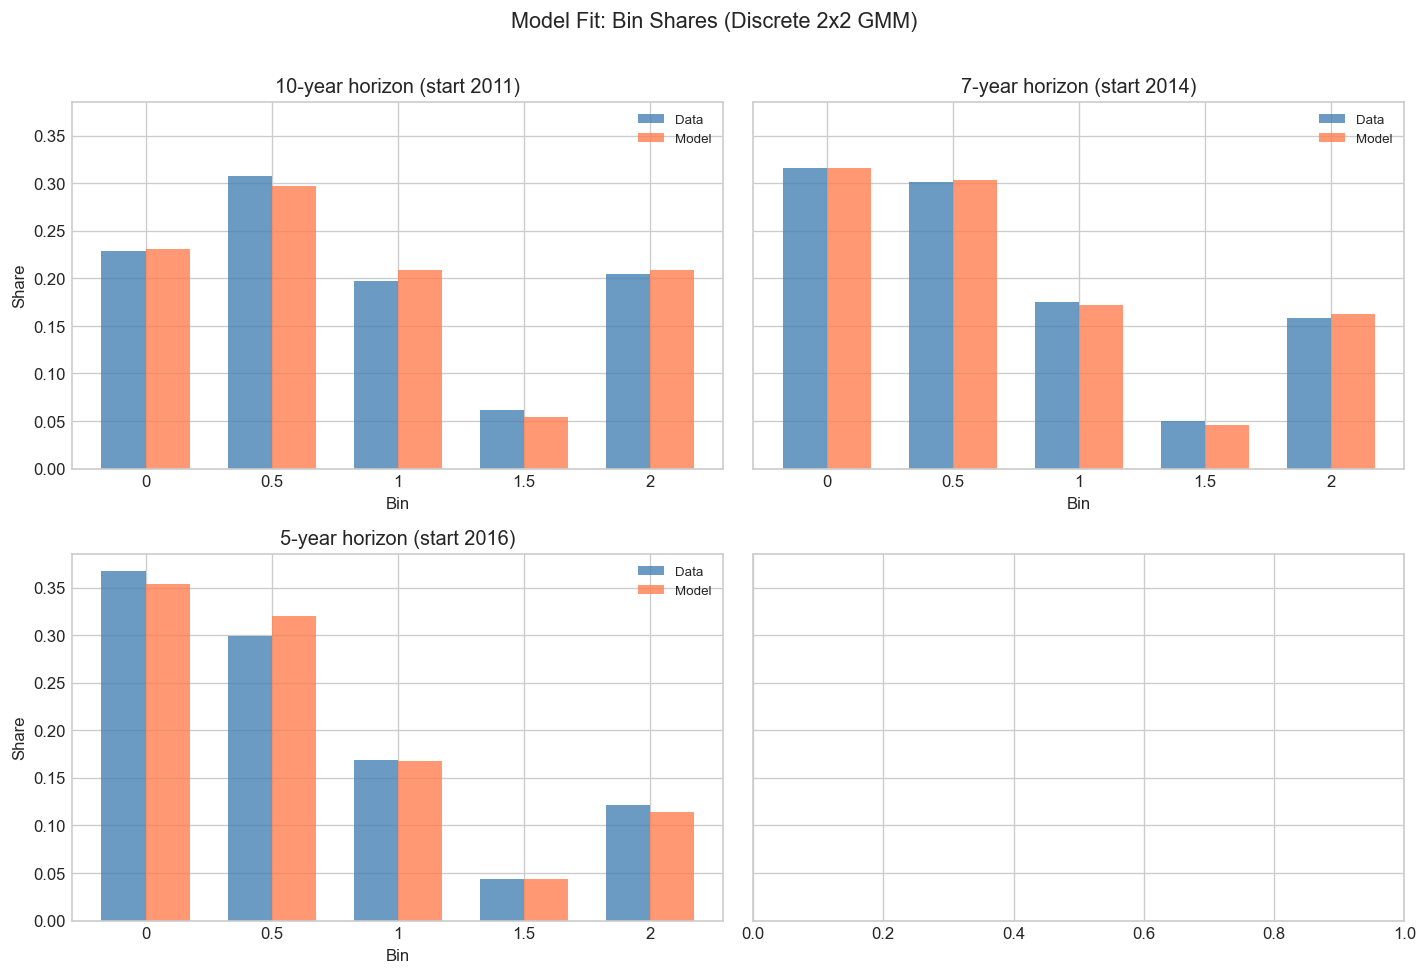

In [11]:
# ---- Model fit: grouped bar chart ----
os.makedirs('./sample_selection', exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
bar_w = 0.35
x = np.arange(5)

for idx, (ax, year, T) in enumerate(zip(axes.flat, YEARS, HORIZONS)):
    ax.bar(x - bar_w/2, data_shares[idx], bar_w, label='Data', color='steelblue', alpha=0.8)
    ax.bar(x + bar_w/2, best_moms[idx], bar_w, label='Model', color='coral', alpha=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(bin_labels)
    ax.set_title(f'{T//12}-year horizon (start {year})')
    ax.set_xlabel('Bin')
    if idx % 2 == 0:
        ax.set_ylabel('Share')
    ax.legend(fontsize=8)

fig.suptitle('Model Fit: Bin Shares (Discrete 2x2 GMM)', fontsize=13, y=1.01)
fig.tight_layout()
# fig.savefig('./output/sample_selection/model_fit_discrete.png', bbox_inches='tight')
plt.show()

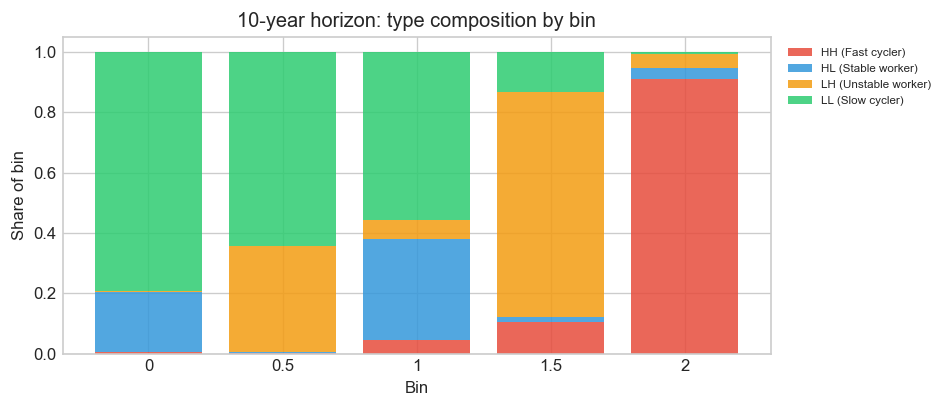

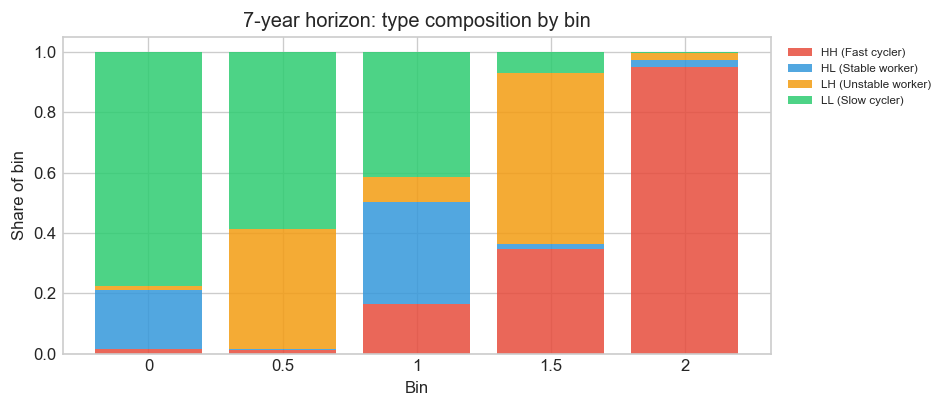

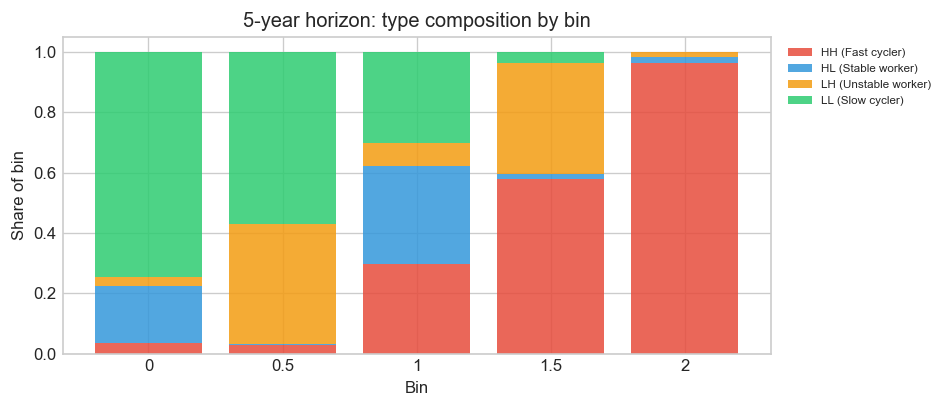

In [12]:
# ---- Type composition of each bin ----

type_rates = [(lam_H, delta_H), (lam_H, delta_L),
              (lam_L, delta_H), (lam_L, delta_L)]
type_shares_list = [pi_HH, pi_HL, pi_LH, pi_LL]
colors_4 = ['#e74c3c', '#3498db', '#f39c12', '#2ecc71']
i=0

for Ti, year in zip(HORIZONS, YEARS):
    per_type = np.zeros((4, 5))
    for t, (lam, delta) in enumerate(type_rates):
        per_type[t] = bin_probs_single(lam, delta, Ti, P_START_U_VEC[i])

    pop_bins = np.zeros(5)
    for t in range(4):
        pop_bins += type_shares_list[t] * per_type[t]

    # P(type | bin) via Bayes
    composition = np.zeros((4, 5))
    for t in range(4):
        for b in range(5):
            if pop_bins[b] > 1e-12:
                composition[t, b] = type_shares_list[t] * per_type[t, b] / pop_bins[b]

    fig, ax = plt.subplots(figsize=(8, 3.5))
    bottom = np.zeros(5)
    for t in range(4):
        ax.bar(bin_labels, composition[t], bottom=bottom,
               label=f'{TYPE_LABELS[t]} ({TYPE_NAMES[t]})', color=colors_4[t], alpha=0.85)
        bottom += composition[t]
    i+=1
    ax.set_ylabel('Share of bin')
    ax.set_xlabel('Bin')
    ax.set_title(f'{Ti//12}-year horizon: type composition by bin')
    ax.legend(fontsize=7, loc='upper left', bbox_to_anchor=(1.01, 1))
    ax.set_ylim(0, 1.05)
    fig.tight_layout()
    # fig.savefig(f'./output/sample_selection/type_composition_{Ti//12}years.png', bbox_inches='tight')
    plt.show()

TYPE COMPOSITION BY BIN (collapsed)

 Horizon       Group       HH       HL       LH       LL    E[lam]    E[del]    Share
----------------------------------------------------------------------------------------
     10y  Population   0.2070   0.1248   0.1688   0.4993   0.03189   0.01455   1.0000
     10y  1 completed Spell   0.0565   0.2688   0.2055   0.4692   0.03135   0.01048   0.2631
     10y  2+ completed Spells   0.9107   0.0369   0.0458   0.0066   0.08291   0.03532   0.2090
          2+ spells/Pop    4.399x    0.295x    0.271x    0.013x   (HH: +339.9%, HL: -70.5%, LH: -72.9%, LL: -98.7%)
          2+ spells gap  E[lam]: 0.08291 vs 0.03189 (+160.0%)   E[del]: 0.03532 vs 0.01455 (+142.7%)
----------------------------------------------------------------------------------------
      7y  Population   0.2070   0.1248   0.1688   0.4993   0.03189   0.01455   1.0000
      7y  1 completed Spell   0.2025   0.2697   0.1853   0.3425   0.04352   0.01498   0.2175
      7y  2+ completed Spells

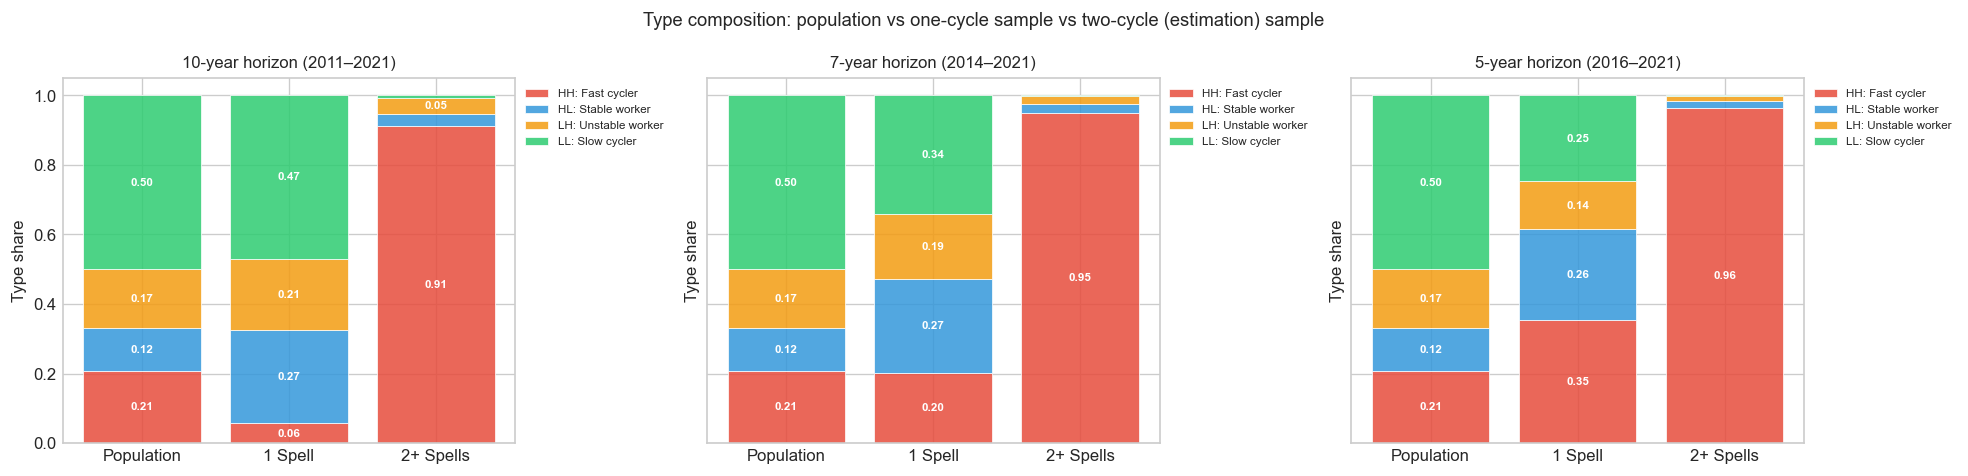

In [13]:
# ---- Paper figure: type composition collapsed to {Population, Bin 1, Bin 2} ----
#
# Bin 0   (no unstable spell started)    } discarded: worker never entered
# Bin 0.5 (one unfinished unstable)      } the unstable-spell sample
# Bin 1   (one complete cycle)           } collapsed to "Bin 1"
# Bin 1.5 (one complete + one unfinished)}
# Bin 2   (two complete cycles)          = estimation sample

type_rates_arr = np.array([(lam_H, delta_H), (lam_H, delta_L),
                            (lam_L, delta_H), (lam_L, delta_L)])
type_shares_arr = np.array([pi_HH, pi_HL, pi_LH, pi_LL])
lam_vals = np.array([lam_H, lam_H, lam_L, lam_L])
del_vals = np.array([delta_H, delta_L, delta_H, delta_L])

colors_4 = ['#e74c3c', '#3498db', '#f39c12', '#2ecc71']
col_labels = ['Population', '1 Spell', '2+ Spells']

def _collapsed_compositions(Ti,p_start_u_i):
    """For horizon Ti return (comp_pop, comp_bin1, comp_bin2), each shape (4,)."""
    per_type = np.array([
        bin_probs_single(lam, delta, Ti, p_start_u_i)
        for lam, delta in type_rates_arr
    ])                                          # shape (4, 5)
    bin1_type = per_type[:, 2] + per_type[:, 3]   # P(bin 1 or 1.5 | type k)
    bin2_type = per_type[:, 4]                     # P(bin 2 | type k)

    pop_bin1 = (type_shares_arr * bin1_type).sum()
    pop_bin2 = (type_shares_arr * bin2_type).sum()

    comp_pop  = type_shares_arr
    comp_bin1 = type_shares_arr * bin1_type / pop_bin1
    comp_bin2 = type_shares_arr * bin2_type / pop_bin2
    return comp_pop, comp_bin1, comp_bin2, pop_bin1, pop_bin2


# ---- Numerical summary for the paper ----
sep = '-' * 88
header = (f'{"Horizon":>8s}  {"Group":>10s}  '
          f'{"HH":>7s}  {"HL":>7s}  {"LH":>7s}  {"LL":>7s}  '
          f'{"E[lam]":>8s}  {"E[del]":>8s}  {"Share":>7s}')

print('TYPE COMPOSITION BY BIN (collapsed)\n')
print(header)
i=0
for Ti, year in zip(HORIZONS, YEARS):
    comp_pop, comp_bin1, comp_bin2, pop_bin1, pop_bin2 = _collapsed_compositions(Ti, P_START_U_VEC[i])
    pop_total = 1.0

    print(sep)
    rows = [
        ('Population', comp_pop,  pop_total),
        ('1 completed Spell',      comp_bin1, pop_bin1),
        ('2+ completed Spells',      comp_bin2, pop_bin2),
    ]
    for label, comp, share in rows:
        e_lam = (comp * lam_vals).sum()
        e_del = (comp * del_vals).sum()
        print(f'{Ti//12:>7d}y  {label:>10s}  ' +
              '  '.join(f'{c:7.4f}' for c in comp) +
              f'  {e_lam:8.5f}  {e_del:8.5f}  {share:7.4f}')

    # Over/under-representation: Bin 2 share relative to population
    ratio = comp_bin2 / comp_pop
    pct   = 100 * (ratio - 1)
    print(f'{"":>8s}  {"2+ spells/Pop":>10s}  ' +
          '  '.join(f'{r:7.3f}x' for r in ratio) +
          f'   ({", ".join(f"{TYPE_LABELS[t]}: {pct[t]:+.1f}%" for t in range(4))})')

    # Mean hazard gap: Bin 2 vs population
    e_lam_pop  = (comp_pop  * lam_vals).sum()
    e_lam_bin2 = (comp_bin2 * lam_vals).sum()
    e_del_pop  = (comp_pop  * del_vals).sum()
    e_del_bin2 = (comp_bin2 * del_vals).sum()
    print(f'{"":>8s}  {"2+ spells gap":>10s}  '
          f'E[lam]: {e_lam_bin2:.5f} vs {e_lam_pop:.5f} '
          f'({100*(e_lam_bin2/e_lam_pop - 1):+.1f}%)   '
          f'E[del]: {e_del_bin2:.5f} vs {e_del_pop:.5f} '
          f'({100*(e_del_bin2/e_del_pop - 1):+.1f}%)')
    i+=1

print(sep)


# ---- Figures ----
# Layout adapts to the number of windows (3 for Germany -> 1x3, no empty panel;
# 4 -> 2x2), so there are never blank subplots.
_n = len(YEARS)
_ncols = _n if _n <= 3 else 2
_nrows = int(np.ceil(_n / _ncols))
fig, axes = plt.subplots(_nrows, _ncols, figsize=(5.5 * _ncols, 4 * _nrows), sharey=True)
axes = np.atleast_1d(axes).flatten()
for i, (Ti, year) in enumerate(zip(HORIZONS, YEARS)):
    ax = axes[i]
    comp_pop, comp_bin1, comp_bin2, pop_bin1, pop_bin2 = _collapsed_compositions(Ti, P_START_U_VEC[i])

    bottom = np.zeros(3)
    for t in range(4):
        heights = np.array([comp_pop[t], comp_bin1[t], comp_bin2[t]])
        ax.bar(col_labels, heights, bottom=bottom,
               label=f'{TYPE_LABELS[t]}: {TYPE_NAMES[t]}',
               color=colors_4[t], alpha=0.85, edgecolor='white', linewidth=0.5)
        # Label inside bar if large enough
        for xi, (h, b) in enumerate(zip(heights, bottom)):
            if h > 0.04:
                ax.text(xi, b + h/2, f'{h:.2f}', ha='center', va='center',
                        fontsize=7, color='white', fontweight='bold')
        bottom += heights
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Type share')
    ax.set_title(f'{Ti//12}-year horizon ({year}–{END_YEAR})', fontsize=10)
    ax.legend(fontsize=7, loc='upper right', bbox_to_anchor=(1.35, 1.0))

# Hide any leftover (unused) panels
for _j in range(_n, len(axes)):
    axes[_j].set_visible(False)

fig.suptitle(
    'Type composition: population vs one-cycle sample vs two-cycle (estimation) sample',
    fontsize=11)
fig.tight_layout()
fig.savefig('./output/sample_selection/type_composition_paper_discrete_germany.png', bbox_inches='tight', dpi=150)
plt.show()

In [14]:
# ---- Implied moments of the discrete distribution ----

share_lam_H = pi_HH + pi_HL
share_lam_L = pi_LH + pi_LL
share_del_H = pi_HH + pi_LH
share_del_L = pi_HL + pi_LL

E_lam = share_lam_H * lam_H + share_lam_L * lam_L
E_del = share_del_H * delta_H + share_del_L * delta_L

E_lam2 = share_lam_H * lam_H**2 + share_lam_L * lam_L**2
E_del2 = share_del_H * delta_H**2 + share_del_L * delta_L**2
Var_lam = E_lam2 - E_lam**2
Var_del = E_del2 - E_del**2

E_lam_del = (pi_HH * lam_H * delta_H + pi_HL * lam_H * delta_L +
             pi_LH * lam_L * delta_H + pi_LL * lam_L * delta_L)
Cov_lam_del = E_lam_del - E_lam * E_del
Corr_lam_del = Cov_lam_del / np.sqrt(Var_lam * Var_del) if Var_lam > 0 and Var_del > 0 else 0

E_inv_lam = share_lam_H / lam_H + share_lam_L / lam_L
E_inv_del = share_del_H / delta_H + share_del_L / delta_L

print('Implied distribution moments:')
print(f'  E[lambda]      = {E_lam:.5f}   (data MLE: {lambda_hat:.5f})')
print(f'  E[delta]       = {E_del:.5f}   (data MLE: {delta_hat:.5f})')
print(f'  SD(lambda)     = {np.sqrt(Var_lam):.5f}')
print(f'  SD(delta)      = {np.sqrt(Var_del):.5f}')
print(f'  Corr(lam,del)  = {Corr_lam_del:.4f}')
print(f'    (cf. lognormal estimate: rho = -0.034)')
print()
print('Implied mean spell durations:')
print(f'  E[1/lambda] = {E_inv_lam:.1f} months  ({E_inv_lam*30:.0f} days)')
print(f'  E[1/delta]  = {E_inv_del:.1f} months  ({E_inv_del*30:.0f} days)')
print()
print('Off-diagonal mass (stable + unstable types):')
print(f'  pi_HL + pi_LH = {pi_HL + pi_LH:.4f}  (negative-correlation types)')
print(f'  pi_HH + pi_LL = {pi_HH + pi_LL:.4f}  (positive-correlation types)')

Implied distribution moments:
  E[lambda]      = 0.03189   (data MLE: nan)
  E[delta]       = 0.01455   (data MLE: nan)
  SD(lambda)     = 0.03901
  SD(delta)      = 0.01732
  Corr(lam,del)  = 0.3609
    (cf. lognormal estimate: rho = -0.034)

Implied mean spell durations:
  E[1/lambda] = 155.8 months  (4674 days)
  E[1/delta]  = 570.7 months  (17122 days)

Off-diagonal mass (stable + unstable types):
  pi_HL + pi_LH = 0.2936  (negative-correlation types)
  pi_HH + pi_LL = 0.7064  (positive-correlation types)


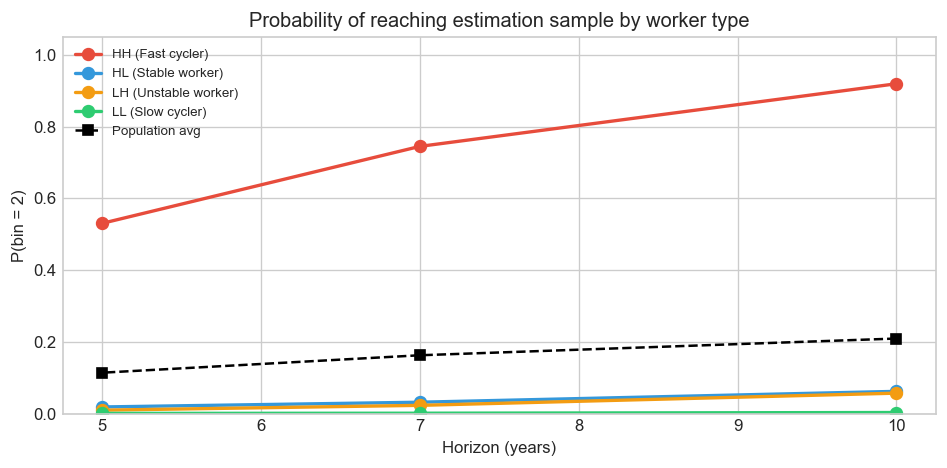

In [15]:
# ---- Selection into sample (bin 2) by type ----

fig, ax = plt.subplots(figsize=(8, 4))

for t, (lam, delta) in enumerate(type_rates):
    p2_by_T = [bin_probs_single(lam, delta, Ti, P_START_U_VEC[i])[4] for i,Ti in enumerate(HORIZONS)]
    ax.plot([Ti//12 for Ti in HORIZONS], p2_by_T, 'o-', color=colors_4[t],
            label=f'{TYPE_LABELS[t]} ({TYPE_NAMES[t]})', lw=2, markersize=7)

pop_p2 = [best_moms[i, 4] for i in range(len(HORIZONS))]
ax.plot([Ti//12 for Ti in HORIZONS], pop_p2, 'ks--', label='Population avg',
        lw=1.5, markersize=6)

ax.set_xlabel('Horizon (years)')
ax.set_ylabel('P(bin = 2)')
ax.set_title('Probability of reaching estimation sample by worker type')
ax.legend(fontsize=8)
ax.set_ylim(0, 1.05)
fig.tight_layout()
# fig.savefig('./output/sample_selection/selection_by_type.png', bbox_inches='tight')
plt.show()

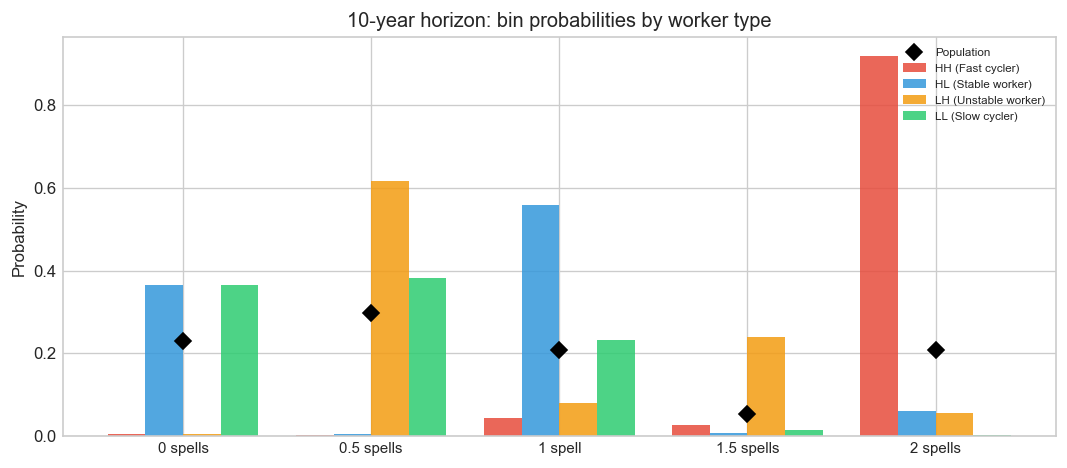

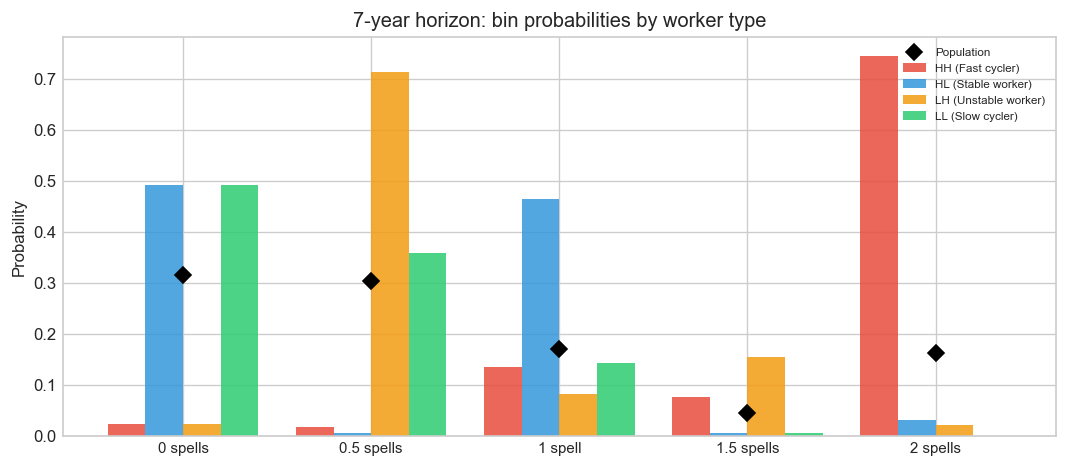

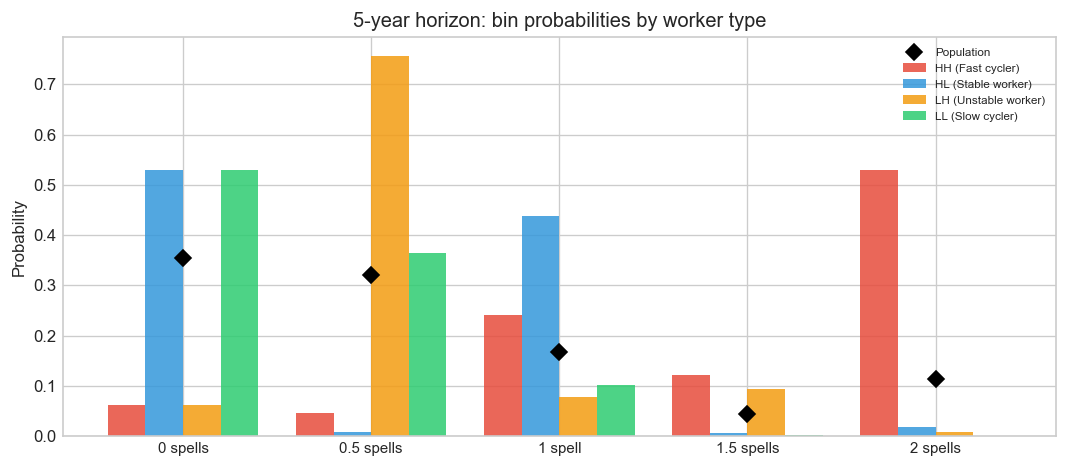

In [16]:
# ---- Paper figures: bin probabilities by type at each horizon ----

BIN_NAMES = ['0 spells', '0.5 spells', '1 spell', '1.5 spells', '2 spells']
i=0
for Ti, year in zip(HORIZONS, YEARS):
    per_type = np.zeros((4, 5))
    for t, (lam, delta) in enumerate(type_rates):
        per_type[t] = bin_probs_single(lam, delta, Ti, P_START_U_VEC[i])

    fig, ax = plt.subplots(figsize=(9, 4))
    x = np.arange(5)
    n_types = 4
    total_w = 0.8
    w = total_w / n_types

    for t in range(n_types):
        offset = (t - n_types/2 + 0.5) * w
        ax.bar(x + offset, per_type[t], w,
               label=f'{TYPE_LABELS[t]} ({TYPE_NAMES[t]})',
               color=colors_4[t], alpha=0.85)
    i+=1
    # Population average as diamonds
    pop_bins = sum(type_shares_list[t] * per_type[t] for t in range(4))
    ax.plot(x, pop_bins, 'kD', markersize=7, label='Population', zorder=5)

    ax.set_xticks(x)
    ax.set_xticklabels(BIN_NAMES, fontsize=9)
    ax.set_ylabel('Probability')
    ax.set_title(f'{Ti//12}-year horizon: bin probabilities by worker type')
    ax.legend(fontsize=7, loc='upper right')
    fig.tight_layout()
    # fig.savefig(f'./output/sample_selection/selection_sim_{Ti//12}year.png', bbox_inches='tight')
    plt.show()

In [17]:
print('=' * 65)
print('ESTIMATION SUMMARY -- Discrete 2x2 GMM')
print('=' * 65)

print(f'\nObjective value: {result.fun:.2f}')
print(f'Converged: {result.success}, nfev: {result.nfev}')

print(f'\n--- Hazard rates ---')
print(f'  lambda_H = {lam_H:.5f}  (mean unstable dur = {1/lam_H:.1f} months)')
print(f'  lambda_L = {lam_L:.5f}  (mean unstable dur = {1/lam_L:.1f} months)')
print(f'  delta_H  = {delta_H:.5f}  (mean stable dur   = {1/delta_H:.1f} months)')
print(f'  delta_L  = {delta_L:.5f}  (mean stable dur   = {1/delta_L:.1f} months)')

print(f'\n--- Type shares ---')
for lab, nm, sh in zip(TYPE_LABELS, TYPE_NAMES, [pi_HH, pi_HL, pi_LH, pi_LL]):
    print(f'  {lab}  {sh:7.4f}  {nm}')

print(f'\n--- Implied moments ---')
print(f'  E[lambda]     = {E_lam:.5f}  (data: {lambda_hat:.5f})')
print(f'  E[delta]      = {E_del:.5f}  (data: {delta_hat:.5f})')
print(f'  Corr(lam,del) = {Corr_lam_del:.4f}')
print(f'  E[unstable spell dur] = {E_inv_lam:.1f} months')
print(f'  E[stable spell dur]   = {E_inv_del:.1f} months')

print(f'\n--- Interpretation ---')
if pi_HL + pi_LH > pi_HH + pi_LL:
    print(f'  Off-diagonal types dominate ({pi_HL+pi_LH:.1%} vs {pi_HH+pi_LL:.1%})')
    print(f'  -> Supports "stable vs unstable" worker types (negative correlation)')
else:
    print(f'  Diagonal types dominate ({pi_HH+pi_LL:.1%} vs {pi_HL+pi_LH:.1%})')
    print(f'  -> Supports "fast vs slow" worker types (positive correlation)')

ESTIMATION SUMMARY -- Discrete 2x2 GMM

Objective value: 5246.09
Converged: True, nfev: 52874

--- Hazard rates ---
  lambda_H = 0.08725  (mean unstable dur = 11.5 months)
  lambda_L = 0.00440  (mean unstable dur = 227.5 months)
  delta_H  = 0.03687  (mean stable dur   = 27.1 months)
  delta_L  = 0.00111  (mean stable dur   = 898.1 months)

--- Type shares ---
  HH   0.2070  Fast cycler
  HL   0.1248  Stable worker
  LH   0.1688  Unstable worker
  LL   0.4993  Slow cycler

--- Implied moments ---
  E[lambda]     = 0.03189  (data: nan)
  E[delta]      = 0.01455  (data: nan)
  Corr(lam,del) = 0.3609
  E[unstable spell dur] = 155.8 months
  E[stable spell dur]   = 570.7 months

--- Interpretation ---
  Diagonal types dominate (70.6% vs 29.4%)
  -> Supports "fast vs slow" worker types (positive correlation)


In [18]:
# ── Auto-rebuild the sample-selection LaTeX tables ───────────────────────────
# Only fires once BOTH countries' JSONs exist, so run order doesn't matter.
import os, subprocess, sys

_needed  = {c: f"output/sample_selection/selection_{c}.json" for c in ("spain", "germany")}
_missing = [c for c, p in _needed.items() if not os.path.exists(p)]

if _missing:
    print("Skipping tex rebuild — still missing:",
          ", ".join(_needed[c] for c in _missing))
    print("Run the other sample-selection notebook, then re-run this cell.")
else:
    r = subprocess.run([sys.executable, "sample_selection_tables.py"],
                       capture_output=True, text=True)
    print(r.stdout or "", r.stderr or "", sep="")
    print("tex rebuild OK" if r.returncode == 0
          else f"tex rebuild FAILED (exit {r.returncode})")

Skipping tex rebuild — still missing: output/sample_selection/selection_spain.json, output/sample_selection/selection_germany.json
Run the other sample-selection notebook, then re-run this cell.


## Simulation

In [ ]:
from scipy.stats import expon

In [ ]:
def variance_decomp(df):
    data_ht = df.copy()
    Ns = df.size
    data_ht['mu_i'] = (data_ht.n1 + data_ht.n2)/2
    data_ht['mu_y'] = np.sum((data_ht.n1 + data_ht.n2))/(2*Ns)
    
    data_ht['sig_i'] = (data_ht.n1 - data_ht.n2)**2/2
    data_ht['sig_y'] = np.sum((data_ht.n1**2 + data_ht.n2**2 - 2*data_ht.mu_y**2))/(2*Ns-1)
    
    data_ht['sig_w'] = np.sum(data_ht.sig_i)/Ns
    data_ht['sig_b'] = np.sum(data_ht.mu_i**2 - 0.5*data_ht.sig_i)/Ns - data_ht.mu_y**2 + (1/(2*Ns))*data_ht.sig_y
    
    data_ht['sig_c'] = np.sum(data_ht.mu_i**2 - 0.5*data_ht.sig_i)/Ns
    data_ht['sig_e'] = np.sum(1.5*data_ht.sig_i - data_ht.mu_i**2)/Ns
    return data_ht

In [15]:
type_rates = [(lam_H, delta_H), (lam_H, delta_L),
              (lam_L, delta_H), (lam_L, delta_L)]
type_shares_list = [pi_HH, pi_HL, pi_LH, pi_LL]
i=0
composition_dic = {}
for Ti, year in zip(HORIZONS, YEARS):
    per_type = np.zeros((4, 5))
    for t, (lam, delta) in enumerate(type_rates):
        per_type[t] = bin_probs_single(lam, delta, Ti, P_START_U_VEC[i])

    pop_bins = np.zeros(5)
    for t in range(4):
        pop_bins += type_shares_list[t] * per_type[t]

    # P(type | bin) via Bayes
    composition = np.zeros((4, 5))
    for t in range(4):
        for b in range(5):
            if pop_bins[b] > 1e-12:
                composition[t, b] = type_shares_list[t] * per_type[t, b] / pop_bins[b]
    composition_dic[year] = composition
    i+=1

In [16]:
Ns = 100000

decomp_sim = {}
for year in YEARS:
    share_high = int(np.sum(composition_dic[year][:2,-1])*Ns)
    
    sample_fast = expon.rvs(scale=1/lam_H, size=(share_high,2))
    sample_slow = expon.rvs(scale=1/lam_L, size=(Ns-share_high,2))
    
    sample_ht = np.vstack((sample_fast,sample_slow))
    
    data_ht = pd.DataFrame(sample_ht, columns=['n1','n2'])
    decomp_sim[year] = variance_decomp(data_ht)

    print('Year {}'.format(year))
    print('Share high lambda in the 2+ spell bin: {:,.2f}'.format(np.sum(composition_dic[year][:2,-1])))
    print('Share duration dependence:  {:,.4f}'.format(decomp_sim[year].sig_e.iloc[0]/decomp_sim[year].sig_y.iloc[0]))
    print('Share heterogeneity:  {:,.4f} \n'.format(decomp_sim[year].sig_b.iloc[0]/decomp_sim[year].sig_y.iloc[0]))

# data_ht.head()



# ============================================================================
# Export computed quantities -> output/sample_selection/selection_<country>.json
# (consumed by sample_selection_tables.py to build output/tables/sample_selection_tables.tex)
# ============================================================================
import json as _json

_COUNTRY = "Germany" if 2014 in YEARS else "Spain"
_TYPES = ['HH', 'HL', 'LH', 'LL']

def _group_dict(comp, share):
    return {**{t: float(comp[k]) for k, t in enumerate(_TYPES)},
            "Elam": float((comp * lam_vals).sum()),
            "Edel": float((comp * del_vals).sum()),
            "share": float(share)}

_windows_out = []
for _i, (_Ti, _yr) in enumerate(zip(HORIZONS, YEARS)):
    cp, c1, c2, p1, p2 = _collapsed_compositions(_Ti, P_START_U_VEC[_i])
    _windows_out.append({
        "horizon": int(round(_Ti / 12)), "year": int(_yr),
        "population": _group_dict(cp, 1.0),
        "one_spell":  _group_dict(c1, p1),
        "two_spell":  _group_dict(c2, p2),
        "ratio": {t: float(c2[k] / cp[k]) if cp[k] > 0 else 0.0
                  for k, t in enumerate(_TYPES)},
    })

_dd_out = [{"horizon": int(round(HORIZONS[_i] / 12)),
            "fast_cycler_share": float(np.sum(composition_dic[_yr][:2, -1])),
            "dd_share": float(decomp_sim[_yr].sig_e.iloc[0] / decomp_sim[_yr].sig_y.iloc[0]),
            "het_share": float(decomp_sim[_yr].sig_b.iloc[0] / decomp_sim[_yr].sig_y.iloc[0])}
           for _i, _yr in enumerate(YEARS)]

_params = {"lam_H": float(lam_H), "lam_L": float(lam_L),
           "delta_H": float(delta_H), "delta_L": float(delta_L),
           "pi_HH": float(pi_HH), "pi_HL": float(pi_HL),
           "pi_LH": float(pi_LH), "pi_LL": float(pi_LL)}

_bins_out = [{"horizon": int(round(HORIZONS[_i] / 12)), "year": int(_yr),
              "shares": [float(x) for x in data_shares[_i]],
              "N": int(round(float(data_N[_i])))}
             for _i, _yr in enumerate(YEARS)]

os.makedirs("sample_selection", exist_ok=True)
with open("output/sample_selection/selection_{}.json".format(_COUNTRY.lower()), "w") as _f:
    _json.dump({"country": _COUNTRY, "end_year": int(END_YEAR),
                "params": _params, "bin_shares": _bins_out,
                "windows": _windows_out, "dd": _dd_out}, _f, indent=2)
print("Wrote output/sample_selection/selection_{}.json".format(_COUNTRY.lower()))

NameError: name 'expon' is not defined